## Importing the Required Libraries

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as shc
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.datasets import load_iris

## Loading the Data

In [37]:
iris = load_iris()
X = iris.data
y = iris.target

In [38]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
X_pca = pd.DataFrame(X_pca, columns=['P1', 'P2'])

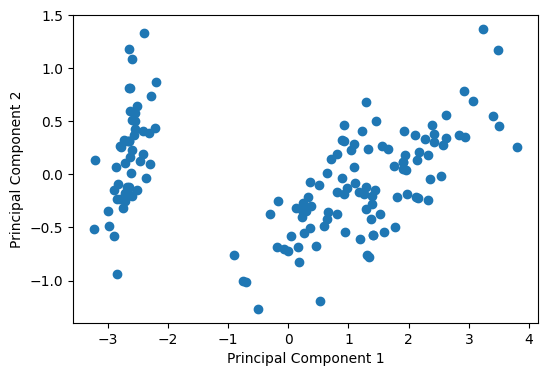

In [39]:
plt.figure(figsize=(6, 4))
plt.scatter(X_pca['P1'], X_pca['P2'])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

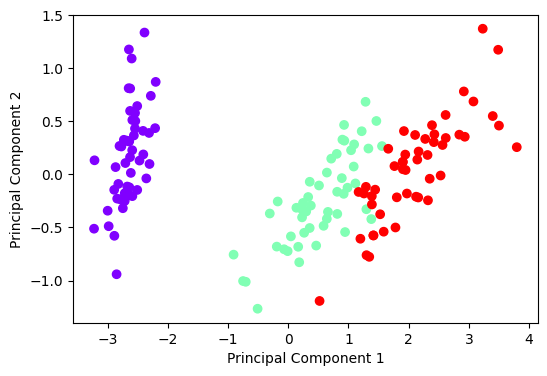

In [40]:
plt.figure(figsize=(6, 4))
plt.scatter(X_pca['P1'], X_pca['P2'], c=y, cmap='rainbow')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

# Clusterign using 2-D Data

## Preparing Dendograms
A dendrogram helps us decide how many clusters to choose. To find the optimal number of clusters in a dendrogram, look for the largest gap between the horizontal lines. Draw a horizontal line across this gap. The number of branches crossed by this line gives the optimal number of clusters.

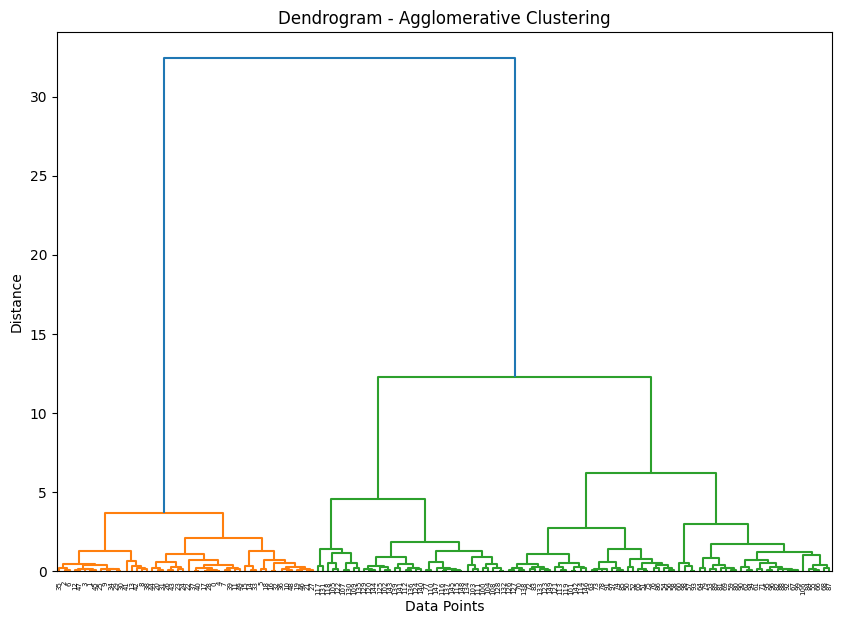

In [41]:
plt.figure(figsize=(10, 7))
plt.title('Dendrogram - Agglomerative Clustering')
shc.dendrogram(shc.linkage(X_pca, method='ward'))
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

## Agglomerative Clustering

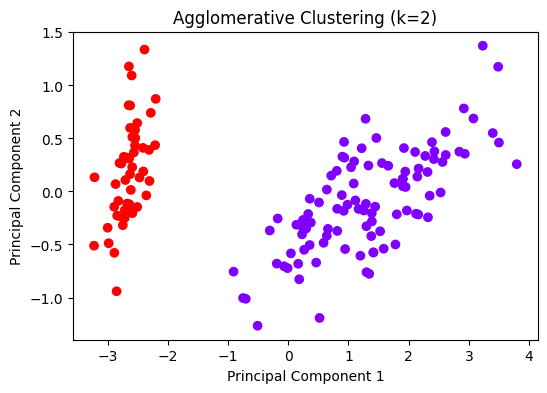

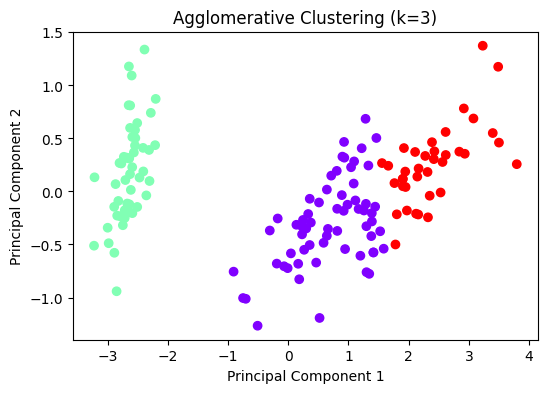

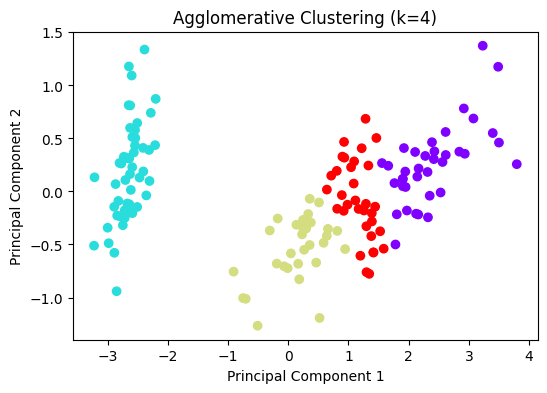

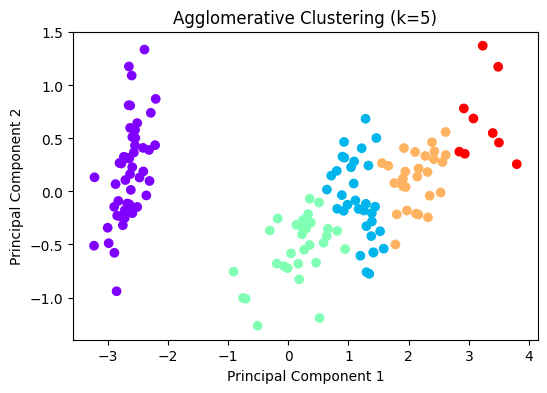

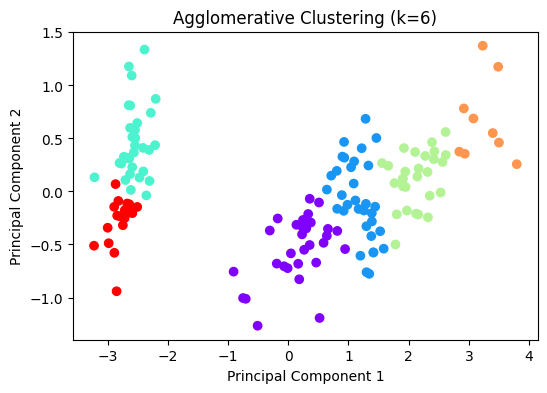

In [42]:
for k in range(2, 7):
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X_pca)

    plt.figure(figsize=(6, 4))
    plt.scatter(X_pca['P1'], X_pca['P2'], c=labels, cmap='rainbow')
    plt.title(f'Agglomerative Clustering (k={k})')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.show()

## Evaluate Models
[Silhouette score](https://en.wikipedia.org/wiki/Silhouette_(clustering)) tells us how well the data has been grouped. The Higher the score the better is model.

Silhouette Score for k=2: 0.7112
Silhouette Score for k=3: 0.5985
Silhouette Score for k=4: 0.5410
Silhouette Score for k=5: 0.5488
Silhouette Score for k=6: 0.4328


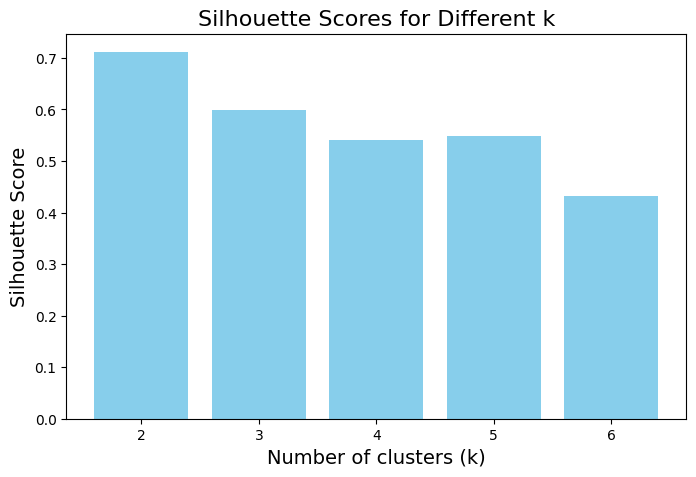

In [43]:
silhouette_scores = []

for k in range(2, 7):
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)
    silhouette_scores.append(score)
    print(f'Silhouette Score for k={k}: {score:.4f}')

# Plotting the scores
plt.figure(figsize=(8, 5))
plt.bar(range(2, 7), silhouette_scores, color='skyblue')
plt.xlabel('Number of clusters (k)', fontsize=14)
plt.ylabel('Silhouette Score', fontsize=14)
plt.title('Silhouette Scores for Different k', fontsize=16)
plt.show()


# Clusterign using Multidimentional Data

## Preparing Dendograms
A dendrogram helps us decide how many clusters to choose. To find the optimal number of clusters in a dendrogram, look for the largest gap between the horizontal lines. Draw a horizontal line across this gap. The number of branches crossed by this line gives the optimal number of clusters.

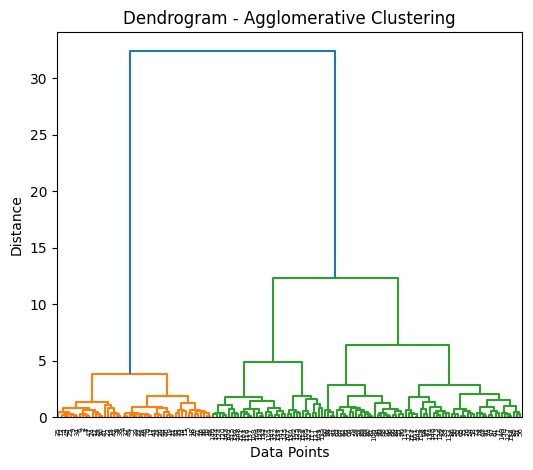

In [44]:
plt.figure(figsize=(6, 5))
plt.title('Dendrogram - Agglomerative Clustering')
shc.dendrogram(shc.linkage(X, method='ward'))
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

## Agglomerative Clustering

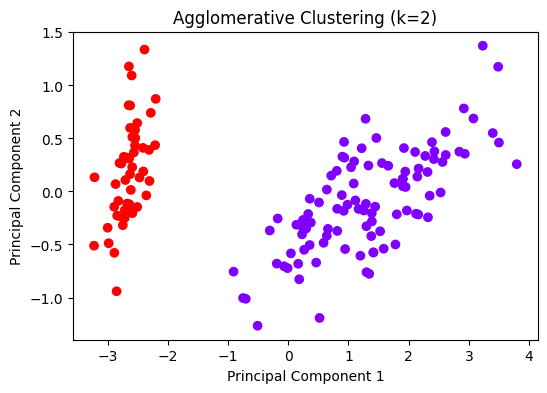

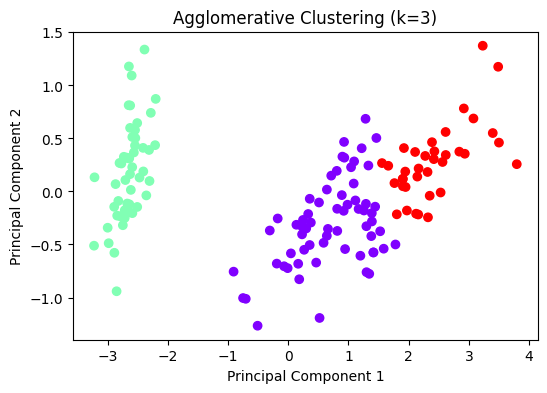

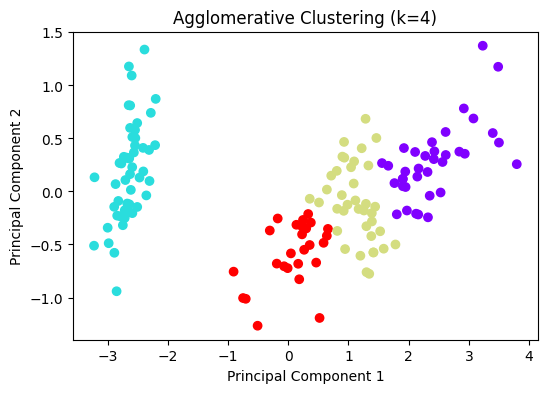

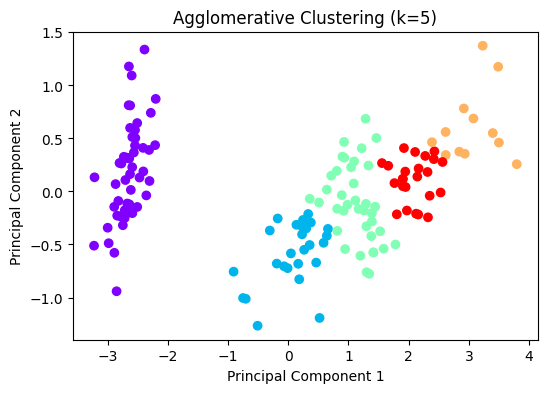

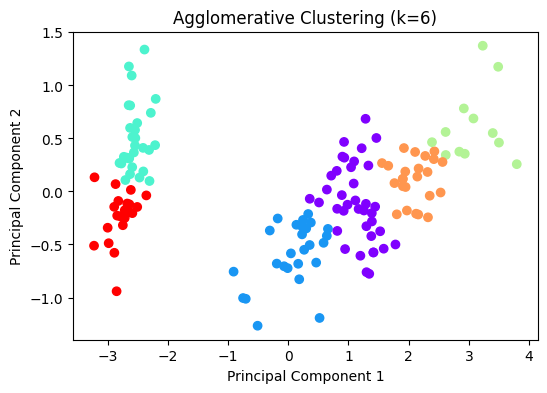

In [45]:
for k in range(2, 7):
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X)

    plt.figure(figsize=(6, 4))
    plt.scatter(X_pca['P1'], X_pca['P2'], c=labels, cmap='rainbow')
    plt.title(f'Agglomerative Clustering (k={k})')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.show()

## Evaluate Models
[Silhouette score](https://en.wikipedia.org/wiki/Silhouette_(clustering)) tells us how well the data has been grouped. The Higher the score the better is model.

Silhouette Score for k=2: 0.6867
Silhouette Score for k=3: 0.5543
Silhouette Score for k=4: 0.4890
Silhouette Score for k=5: 0.4844
Silhouette Score for k=6: 0.3592


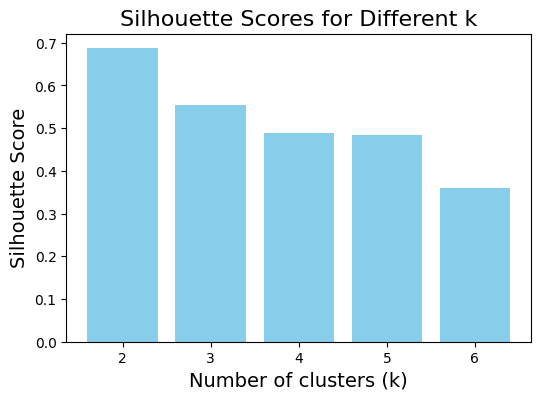

In [46]:
silhouette_scores = []

for k in range(2, 7):
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)
    print(f'Silhouette Score for k={k}: {score:.4f}')

# Plotting the scores
plt.figure(figsize=(6, 4))
plt.bar(range(2, 7), silhouette_scores, color='skyblue')
plt.xlabel('Number of clusters (k)', fontsize=14)
plt.ylabel('Silhouette Score', fontsize=14)
plt.title('Silhouette Scores for Different k', fontsize=16)
plt.show()
